# 📊 Trabajo Práctico Estadística Descriptiva

El presente trabajo se desarrolla a partir de la base de datos **Matrículas de Educación Superior de la Región de O'Higgins (2021)**, la cual registra información de los **estudiantes matriculados** en instituciones de educación superior de la región. La base contiene más de **22.000 registros** con **28 variables**, entre las que se encuentran datos personales del estudiante (género, edad), información de la carrera (nombre, tipo de plan, nivel, área de conocimiento, duración), valores asociados (arancel y matrícula), la institución de origen y su ubicación (región, provincia y comuna de la sede).

---

## 📊 Paso 0: Instalación e importación de librerías

Se **instalan y se importan las librerías** necesarias para el análisis de los datos.

### ⚙️ Instalación de librerías

En caso de que alguna librería no esté instalada, se puede instalar desde la terminal con el comando **pip**:

```bash
pip install numpy
pip install pandas
pip install matplotlib
```

O bien, instalar todas a la vez:

```bash
pip install numpy pandas matplotlib
```

### 📥 Importación de librerías

Una vez instaladas, se importan de la siguiente manera:

```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from scipy.stats import skew, kurtosis, norm
```

---


In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from scipy.stats import skew, kurtosis, norm

---

## 📊 Paso 1: Exploración de la base de datos

En esta etapa se identifican y describen las **variables** que componen la base de datos, junto con su **tipo** y si **se utilizarán** en el trabajo práctico.

---

#### 📋 Leyenda de tipos de variable

| Tipo de variable | Descripción |
| --- | --- |
| **Cualitativa Nominal** | Categorías **sin orden** entre sí (ej. Género, Institución). |
| **Cualitativa Ordinal** | Categorías con **orden** o jerarquía (ej. Rango de Edad, Jornada). |
| **Cuantitativa Discreta** | Valores **numéricos enteros** (ej. Edad, Semestres). |
| **Cuantitativa Continua** | Valores **numéricos con decimales** (ej. Peso, Estatura). |

---

### 🗂️ Variables de la base de datos

| Variable | Descripción | Tipo Variable | ¿Usar? |
| --- | --- | --- | --- |
| **ID** | Identificador del matriculado. | Cuantitativa Discreta | |
| Género | Género del matriculado. | Cualitativa Nominal |   |
| Edad | Edad del estudiante. | Cuantitativa Discreta |  **✓** |
| Rango de Edad | Rango de edad al que pertenece la edad del matriculado. | Cuantitativa Discreta | |
| Año de Ingreso | Año de ingreso a primer año. | Cuantitativa Discreta |  **✓**  |
| Semestre de Ingreso | Semestre del año en que el matriculado ingresó a la carrera. | Cualitativa Ordinal | |
| Tipo de Institución | Nombre completo de la institución. | Cualitativa Nominal | |
| Acreditación Institucional | Situación de acreditación de la institución al 30 de abril del año en proceso. | Cualitativa Nominal | |
| Periodo de Acreditación | Fecha de inicio y término de la acreditación institucional. | Cuantitativa Continua | |
| Años de Acreditación | Número de años por la que fue acreditada la institución. | Cuantitativa Continua | |
| Nombre de Carrera | Nombre completo de la carrera o programa. | Cualitativa Nominal |  **✓** |
| Requisito de Ingreso | Requisito específico para ingresar a determinada carrera o programa. | Cualitativa Ordinal | |
| Vía de Ingreso | Forma de ingreso a la carrera o programa. | Cualitativa Nominal | |
| Modalidad | Modo en que se imparte la carrera o programa. | Cualitativa Nominal | |
| Jornada | Jornada en que se imparte la carrera o programa. | Cualitativa Nominal | |
| Tipo de Plan de Carrera | Distinción dada por el tipo de plan que posee la carrera o programa. | Cualitativa Nominal |  |
| Nivel de Estudio de Carrera | Clasificación del nivel global al que pertenecen los estudios de la carrera o programa. | Cualitativa Ordinal | |
| Nivel de Carrera | Clasificación del nivel específico al que pertenecen los estudios de la carrera o programa. | Cualitativa Nominal  | |
| Área de Conocimiento | Categorización CINE-UNESCO de la carrera o programa. | Cualitativa Nominal |**✓**|
| Duración Plan de Estudio (Semestres) | Duración de la carrera o programa informada en número de semestres, sin incluir el proceso de titulación cuando está fuera del plan de estudios. | Cuantitativa Continua | |
| Duración Proceso de Titulación (Semestres) | Duración en semestres del proceso de titulación que deben realizar los estudiantes para obtener el título o grado de la carrera o programa. | Cuantitativa Continua | |
| Duración Total de Carrera (Semestres) | Duración teórica o formal en semestres de la carrera o programa, desde el momento en que el estudiante ingresa al primer año hasta que obtiene el título o grado terminal de la misma. | Cuantitativa Continua | |
| Valor Matrícula (Pesos) | Valor en pesos que el estudiante debe pagar para hacer efectiva su matrícula. | Cuantitativa Continua | **✓** |
| Valor Arancel (Pesos) | Arancel anual de la carrera o programa. | Cuantitativa Continua |  **✓** |
| Región Sede | Región donde se ubica la sede en la cual se imparte la carrera. | Cualitativa Nominal | |
| Provincia Sede | Nombre de la provincia en que se imparte la carrera o programa. | Cualitativa Nominal | |
| Comuna Sede | Comuna donde se ubica la sede en la cual se imparte la carrera. | Cualitativa Nominal | |

> **Nota:** Marcaremos con **✓** en la columna *¿Usar?* las variables que usaremos en el desarrollo del trabajo práctico.

---

---

## 📊 Paso 2: Estudio de la distribución de los datos

En este paso se analiza la **distribución** de las variables seleccionadas en el Paso 1. Para ello se elaboran **tablas de frecuencias** y **gráficos** (histogramas, diagramas de barras, etc.).

#### 📋 Actividades

- Elaborar **gráficos** que representen la información más importante (barras, sectores, histogramas).
- Realizar **tablas de frecuencia** para al menos 2 variables.

#### ❓ Preguntas guía

- ¿Cuál es la **distribución por género**?
- ¿Cuál es la **distribución de edades**?
- ¿Cómo se **reparte la matrícula** según tipo de institución o jornada?

---


---

## 📊 Generación del DataFrame

Se **genera un DataFrame** a partir de la base de datos en formato **Excel**, con el objetivo de obtener una vista más dinámica de los datos y poder trabajar sobre ellos de forma más práctica.

---


In [2]:
informe = pd.read_excel("08_MATRICULAS_ED_SUPERIOR_B_OHIGGINS_2021.xlsx")
informe = pd.DataFrame(informe)
informe.head(5)

,ID,GENERO,EDAD,RANGO EDAD,AÑO INGRESO,SEMESTRE INGRESO,TIPO DE INSTITUCION,NOMBRE DE INSTITUCION,ACREDITACION INSTITUCIONAL,PERIODO DE ACREDITACION,...,NIVEL CARRERA,AREA CONOCIMIENTO,DURACION PLAN DE ESTUDIO (SEMESTRES),DURACION PROCESO TITULACION (SEMESTRES),DURACION TOTAL CARRERA (SEMESTRES),VALOR MATRICULA (PESOS),VALOR ARANCEL (PESOS),REGION SEDE,PROVINCIA SEDE,COMUNA SEDE
0,43,Femenino,19,15 a 19,2021,Primer semestre,Centros de Formacion Tecnica,CFT SANTO TOMAS,ACREDITADA,20/12/2019 AL 20/12/2024,...,Carreras Tecnicas,Salud,5,0,5,64000,1990000,Lib. Gral B. O'Higgins,Cachapoal,Rancagua
1,46,Masculino,22,20 a 24,2018,Primer semestre,Universidades CRUCH,UNIVERSIDAD DE O'HIGGINS,NO ACREDITADA,NaN,...,Carreras Profesionales,Educacion,10,1,10,267000,2838000,Lib. Gral B. O'Higgins,Cachapoal,Rancagua
2,116,Femenino,21,20 a 24,2021,Primer semestre,Institutos Profesionales,IP IPG,ACREDITADA,25/08/2018 AL 25/08/2021,...,Carreras Profesionales,Educacion,5,1,5,0,1200000,Lib. Gral B. O'Higgins,Cachapoal,Rancagua
3,117,Femenino,21,20 a 24,2019,Primer semestre,Institutos Profesionales,IP SANTO TOMAS,ACREDITADA,20/01/2021 AL 20/01/2026,...,Carreras Profesionales,Agropecuaria,8,0,8,89000,1902000,Lib. Gral B. O'Higgins,Cachapoal,Rancagua
4,133,Femenino,21,20 a 24,2020,Primer semestre,Institutos Profesionales,IP LOS LAGOS,NO ACREDITADA,NaN,...,Carreras Profesionales,Administracion y Comercio,9,1,9,121500,1215000,Lib. Gral B. O'Higgins,Colchagua,San Fernando


---

## 📊 Definición de población y muestra

Se **definen la población y la muestra** presentes en el estudio, a partir de la base de datos en formato **Excel**.

### 👥 Población

La **población** presente en este estudio son los estudiantes matriculados en instituciones de **educación superior** de la región de **O'Higgins** en el año **2021**.


### 🎯 Muestra

La **muestra** corresponde a la totalidad de los registros presentes en la base de datos, es decir, los **estudiantes matriculados** considerados para el análisis.


In [3]:
muestra = informe.shape[0]
print(f"La muestra presente en el estudio es de {muestra} estudiantes matriculados en instituciones de educación superior en la región de O'Higgins durante el año 2021")


La muestra presente en el estudio es de 22114 estudiantes matriculados en instituciones de educación superior en la región de O'Higgins durante el año 2021


---

## 📊 Tablas de frecuencia

En esta sección se presentan las **tablas de frecuencia** elaboradas para las variables seleccionadas, junto con su respectiva **interpretación**.

#### 📋 Tabla 1: Frecuencia de la variable cuantitativa continua — Edad


In [4]:

frecuencia = informe.groupby('EDAD').size()
tablaEdad= pd.DataFrame({
    'fi': frecuencia,
    'hi (%)': round(frecuencia/muestra * 100,2),
    'FI': frecuencia.cumsum(),
    'HI (%)': (frecuencia/muestra * 100).cumsum()
})
tablaEdad
tablaEdad.head(10)



,fi,hi (%),FI,HI (%)
EDAD,,,,
17,1,0.00,1,0.004522
18,634,2.87,635,2.871484
19,3427,15.50,4062,18.368454
20,1455,6.58,5517,24.947997
21,2835,12.82,8352,37.767930
22,2351,10.63,10703,48.399204
23,1729,7.82,12432,56.217781
24,1936,8.75,14368,64.972416
25,444,2.01,14812,66.980194


#### 📖 Interpretación 1

A través de esta tabla de frecuencia se puede demostrar que:

- Hay un **6.58 %** de estudiantes matriculados que tienen **20 años**.
- Hay un total de **15.650 estudiantes** matriculados que tienen hasta **26 años**.
- Hay un **70.76 %** de estudiantes matriculados que tienen hasta **26 años**.
- Hay un total de **2.835 estudiantes** matriculados que tienen **21 años**.


#### 📋 Tabla 2: Frecuencia de la variable cualitativa nominal — Nombre de la carrera


In [5]:

frecuencia = informe.groupby('NOMBRE CARRERA').size()
tablaCarrera = pd.DataFrame({
    'fi': frecuencia,
    'hi (%)': round((frecuencia/muestra) *100, 1) 
})
tablaCarrera.loc['Total'] = [tablaCarrera['fi'].sum(), tablaCarrera['hi (%)'].sum()]
tablaCarrera
tablaCarrera.head(10)

,fi,hi (%)
NOMBRE CARRERA,,
ADMINISTRACION DE EMPRESAS,307.0,1.4
ADMINISTRACION PUBLICA,162.0,0.7
AGRONOMIA (PLAN DE CONTINUIDAD),20.0,0.1
ANALISTA PROGRAMADOR,268.0,1.2
ANALISTA PROGRAMADOR COMPUTACIONAL,7.0,0.0
ASISTENTE DE PARVULOS,446.0,2.0
ASISTENTE EN EDUCACION DE PARVULOS,106.0,0.5
ASISTENTE JURIDICO,8.0,0.0
AUDITORIA,215.0,1.0


#### 📖 Interpretación 2

A través de esta tabla de frecuencia (absoluta-relativa) se puede demostrar que:

- Hay un total de **307 estudiantes** matriculados en la carrera **Administración de Empresas**.
- Un **1.2 %** del total de estudiantes se encuentra matriculado en la carrera **Analista Programador**.


#### 📋 Tabla 3: Frecuencia de la variable cuantitativa continua — Valor Matrícula (pesos)


In [6]:
muestra = informe.shape[0]

frecuencia = informe.groupby('VALOR MATRICULA (PESOS)').size()
tablaMatricula= pd.DataFrame({
    'fi': frecuencia,
    'hi (%)': round(frecuencia/muestra * 100,2),
    'FI': frecuencia.cumsum(),
    'HI (%)': round((frecuencia/muestra * 100).cumsum(),2)
})
tablaMatricula

tablaMatricula.head(10)

,fi,hi (%),FI,HI (%)
VALOR MATRICULA (PESOS),,,,
0,657,2.97,657,2.97
50000,63,0.28,720,3.26
62000,38,0.17,758,3.43
64000,1655,7.48,2413,10.91
77000,178,0.80,2591,11.72
85500,26,0.12,2617,11.83
86000,38,0.17,2655,12.01
89000,726,3.28,3381,15.29
99000,206,0.93,3587,16.22


#### 📖 Interpretación 3

A través de esta tabla de frecuencia se puede demostrar que:

- Hay **657 estudiantes** cuya matrícula tiene costo **cero**.
- Hay un **3.28 %** de estudiantes cuya matrícula tiene un costo de **$89.000**.
- Hay un total de **3.606 estudiantes** cuya matrícula llega hasta los **$101.500**.
- Un **10.91 %** de los estudiantes tiene un valor de matrícula de hasta **$64.000**.


#### 📋 Tabla 4: Frecuencia de la variable cuantitativa continua — Valor Arancel (pesos)


In [7]:
frecuencia = informe.groupby('VALOR ARANCEL (PESOS)').size()
tablaArancel= pd.DataFrame({
    'fi': frecuencia,
    'hi (%)': round(frecuencia/muestra * 100,3),
    'FI': frecuencia.cumsum(),
    'HI (%)': round((frecuencia/muestra * 100).cumsum(),3)
})
tablaArancel

tablaArancel.head(10)

,fi,hi (%),FI,HI (%)
VALOR ARANCEL (PESOS),,,,
0,1,0.005,1,0.005
855000,26,0.118,27,0.122
890000,1,0.005,28,0.127
990000,206,0.932,234,1.058
1015000,19,0.086,253,1.144
1050000,136,0.615,389,1.759
1080000,1,0.005,390,1.764
1085000,1,0.005,391,1.768
1102000,1,0.005,392,1.773


#### 📖 Interpretación 4

A través de esta tabla de frecuencia se puede demostrar que:

- Hay **un solo estudiante** que no debe pagar el arancel de su carrera.
- Hay un **0.11 %** de estudiantes cuyo arancel es de **$855.000**.
- Hay **391 estudiantes** cuyo arancel es de hasta **$1.085.000**.
- Un **1.99 %** del total de estudiantes tiene un arancel de hasta **$1.120.000**.


#### 📋 Tabla 5: Frecuencia de la variable cualitativa nominal — Área de Conocimiento


In [8]:
frecuencia = informe.groupby('AREA CONOCIMIENTO').size()
tablaArea = pd.DataFrame({
    'fi': round(frecuencia,1),
    'hi (%)': round((frecuencia/muestra) *100,2) 
})
tablaArea

,fi,hi (%)
AREA CONOCIMIENTO,,
Administracion y Comercio,4100,18.54
Agropecuaria,1427,6.45
Arte y Arquitectura,597,2.70
Ciencias Basicas,2,0.01
Ciencias Sociales,1743,7.88
Derecho,527,2.38
Educacion,3399,15.37
Salud,4012,18.14
Tecnologia,6307,28.52


#### 📖 Interpretación 5

A través de esta tabla de frecuencia (absoluta-relativa) se puede demostrar que:

- Hay **4.012 estudiantes** cuya área de conocimiento es **Salud**.
- Un **28.52 %** del total de estudiantes pertenece al área de conocimiento **Tecnología**.


#### 📋 Tabla 6: Frecuencia de la variable cuantitativa discreta — Año Ingreso

In [9]:
frecuencia = informe.groupby('AÑO INGRESO').size()
tablaIngreso= pd.DataFrame({
    'fi': frecuencia,
    'hi (%)': round(frecuencia/muestra * 100,3),
    'FI': frecuencia.cumsum(),
    'HI (%)': round((frecuencia/muestra * 100).cumsum(),2)
})
tablaIngreso

tablaIngreso.head(10)

,fi,hi (%),FI,HI (%)
AÑO INGRESO,,,,
2007,1,0.005,1,0.00
2008,3,0.014,4,0.02
2009,2,0.009,6,0.03
2010,9,0.041,15,0.07
2011,14,0.063,29,0.13
2012,29,0.131,58,0.26
2013,48,0.217,106,0.48
2014,76,0.344,182,0.82
2015,187,0.846,369,1.67


#### 📖 Interpretación 6

A través de esta tabla de frecuencia (absoluta-relativa) se puede demostrar que:

- En el año **2007** solo **un estudiante** ingresó a su primer año de clases.
- Un **1.74 %** del total de estudiantes ingresó a su primer año de clases en el año **2016**.
- Hasta el año **2016** ingresaron un total de **753 estudiantes** a su primer año de clases.
- Un **1.67 %** del total de estudiantes ingresó a su primer año de clases hasta el año **2015**.


---

## 📊 Gráficos

Se crean **Gráficos** a partir de la base de datos en formato **Excel**, con el objetivo de representar la información más importante de nuestras variables.

---

---

## 📊 Gráfico de Áreas de Conocimiento

---


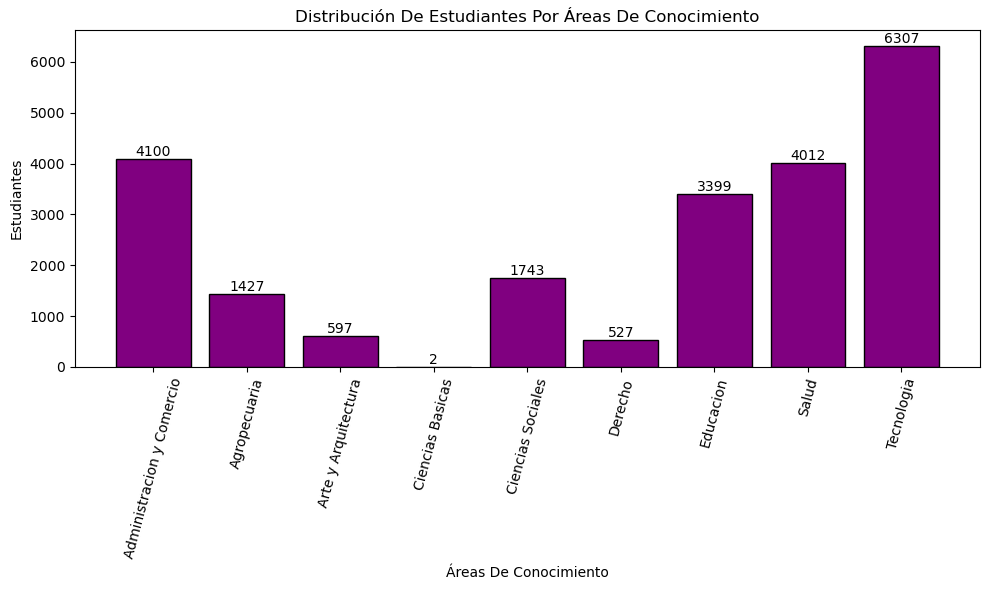

In [10]:

categorias = tablaArea.index
f = tablaArea['fi'] 

fig, ax = plt.subplots(figsize = (10,6))
barras = ax.bar(categorias, f, color = 'purple', edgecolor ='black') 

ax.set_title('Distribución De Estudiantes Por Áreas De Conocimiento')
ax.set_xlabel('Áreas De Conocimiento')
ax.set_ylabel('Estudiantes')
ax.bar_label(barras)

plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


---

## 📊 Gráfico de Distribución De Estudiantes Por Año De Ingreso

---


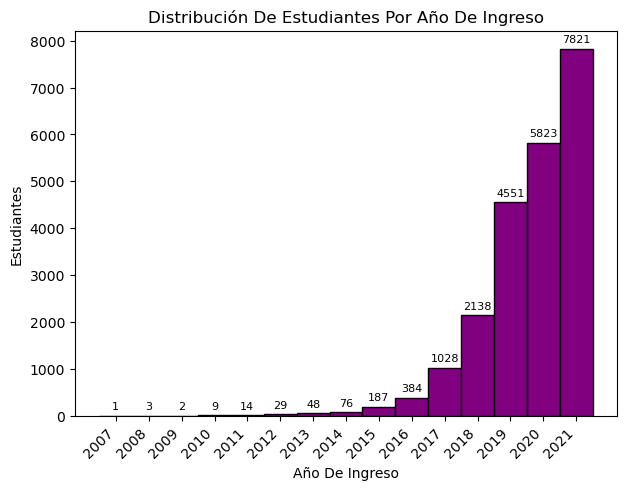

In [11]:
categorias = tablaIngreso.index
f = tablaIngreso['fi']

fig, ax = plt.subplots(figsize = (7, 5))
histograma = ax.bar(categorias.astype(str), f, color = 'purple', edgecolor = 'black', width = 1)

ax.set_title('Distribución De Estudiantes Por Año De Ingreso')
ax.set_xlabel('Año De Ingreso')
ax.set_ylabel('Estudiantes')
ax.bar_label(histograma,  padding = 3, fontsize = 8)
plt.xticks(rotation = 45, ha = 'right')

plt.show()

---

## 📊 Gráfico de Distribución De Estudiantes Por Valor De Matrícula

---


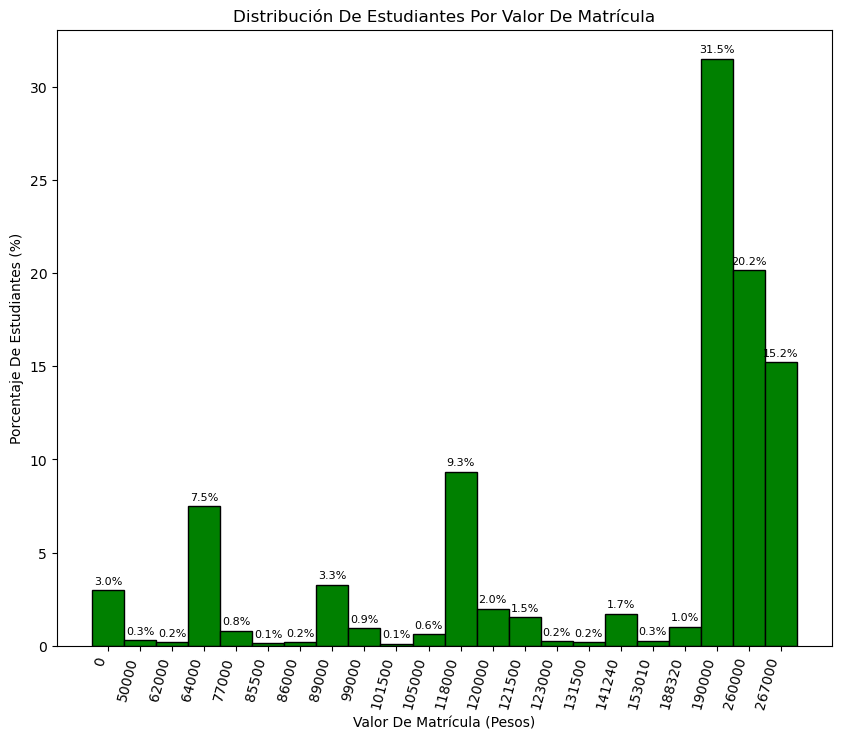

In [12]:
categorias = tablaMatricula.index
f = tablaMatricula['hi (%)']

fig, ax = plt.subplots(figsize = (10, 8))
histograma = ax.bar(categorias.astype(str), f, color = 'green', edgecolor = 'black', width = 1)

ax.set_title('Distribución De Estudiantes Por Valor De Matrícula')
ax.set_xlabel('Valor De Matrícula (Pesos)')
ax.set_ylabel('Porcentaje De Estudiantes (%)')
ax.bar_label(histograma, fmt = '%.1f%%', padding = 3, fontsize = 8)
plt.xticks(rotation = 75, ha = 'right')
plt.show()

---

## 📊 Paso 3: Cálculo de medidas estadísticas

En este paso se **calculan las medidas estadísticas** de las variables numéricas (edad, arancel, matrícula), tanto de tendencia central como de dispersión y posición. Los objetivos son:

- Calcular las **medidas de dispersión**: rango, varianza y desviación estándar.
- Incluir **percentiles** en al menos una variable (por ejemplo: arancel o edad).

#### ❓ Preguntas guía

- ¿Cuál es la **edad promedio** de los estudiantes?
- ¿Qué **arancel** pagan en promedio y cuánto varía entre instituciones?
- ¿En qué **percentil** se encuentra el arancel más alto?

---


---

## 📉 Media, mediana y moda de la variable Edad

---


In [13]:
media = informe['EDAD'].mean()
mediana = informe['EDAD'].median()
moda = informe['EDAD'].mode()
print(f"La media en la edad de los estudiantes matriculados es de", round(media), "años")
print(f"La mediana en la edad de los estudiantes matriculados es de", round(mediana), "años")
print(f"La edad más común entre los estudiantes matriculados es de {moda[0]} años")


La media en la edad de los estudiantes matriculados es de 25 años
La mediana en la edad de los estudiantes matriculados es de 23 años
La edad más común entre los estudiantes matriculados es de 19 años


---

## 📉 Media, mediana y moda de la variable Arancel (pesos)

---


In [14]:
media = informe['VALOR ARANCEL (PESOS)'].mean()
mediana = informe['VALOR ARANCEL (PESOS)'].median()
moda = informe['VALOR ARANCEL (PESOS)'].mode()

print(f"La media de los aranceles (en pesos) de los estudiantes es de $", round(media))
print(f"La mediana de los aranceles (en pesos) de los estudiantes es de $", round(mediana))
print(f"El arancel más común entre los estudiantes es $ {moda[0]}")


La media de los aranceles (en pesos) de los estudiantes es de $ 2187377
La mediana de los aranceles (en pesos) de los estudiantes es de $ 2020000
El arancel más común entre los estudiantes es $ 2180000


---

## 📉 Media, mediana y moda de la variable Matrícula (pesos)

---


In [15]:
media = informe['VALOR MATRICULA (PESOS)'].mean()
mediana = informe['VALOR MATRICULA (PESOS)'].median()
moda = informe['VALOR MATRICULA (PESOS)'].mode()
print(f"La media del valor de la matrícula de los estudiantes es de $ {media:.0f}")
print(f"La mediana del valor de la matrícula de los estudiantes es de $", round(mediana))
print(f"El valor de matrícula más común entre los estudiantes es $ {moda[0]}")


La media del valor de la matrícula de los estudiantes es de $ 183804
La mediana del valor de la matrícula de los estudiantes es de $ 190000
El valor de matrícula más común entre los estudiantes es $ 190000


---

## 📉 Percentiles

---


In [16]:
#1
percentil_25 = informe['EDAD'].quantile(25/100)
print(f"El 25% del total de estudiantes tienen una edad menor a {percentil_25:.0f} años")

El 25% del total de estudiantes tienen una edad menor a 21 años


In [17]:
#2
percentil_80 = informe['VALOR ARANCEL (PESOS)'].quantile(80/100)
print(f"El 80% del valor del arancel es de a lo más de ${percentil_80:.0f}")

El 80% del valor del arancel es de a lo más de $2450000


---

## 📊 Paso 4: Respuesta a las preguntas de investigación

En este paso se **responden las preguntas de investigación obligatorias** a partir del análisis de los datos realizado en los pasos anteriores, apoyándose en los resultados obtenidos (tablas, gráficos y medidas estadísticas).

#### 🔍 Preguntas de investigación

1. ¿Existen **áreas del conocimiento** donde las carreras sean más costosas?
   - Comparar los **aranceles promedio** según área de conocimiento.
2. ¿Influye la **edad** en el **tipo de institución** a la que ingresan los estudiantes?
   - Relacionar los **rangos de edad** con universidades CRUCH o privadas.
3. ¿Se observan carreras con aranceles significativamente más altos que el promedio? ¿A qué se puede deber?
   - Identificar cuáles y buscar una explicación (ejemplo: duración, prestigio de la institución, tipo de área).

---


In [18]:
# 1

tabla = informe.groupby('AREA CONOCIMIENTO')['VALOR ARANCEL (PESOS)'].agg(['mean', 'std'])

tabla['CV %'] = (tabla['std'] / tabla['mean']) * 100

round(tabla)


,mean,std,CV %
AREA CONOCIMIENTO,,,
Administracion y Comercio,2021764.0,470582.0,23.0
Agropecuaria,2379641.0,852901.0,36.0
Arte y Arquitectura,1886657.0,303579.0,16.0
Ciencias Basicas,4323000.0,0.0,0.0
Ciencias Sociales,2100580.0,777399.0,37.0
Derecho,3047961.0,911903.0,30.0
Educacion,1899885.0,633594.0,33.0
Salud,2590611.0,915849.0,35.0
Tecnologia,2129835.0,738262.0,35.0


Claramente hay áreas que tienen un costo más elevado, como Ciencias Básicas, con un valor de $4.323.000, y Derecho, con un promedio de $3.047.961.

In [19]:
# 2

rango = informe['EDAD'].max() - informe['EDAD'].min()
print(f"Rango de edades: {rango}")

tabla = informe.groupby('TIPO DE INSTITUCION')['EDAD'].agg(['mean', 'std'])
tabla['CV %'] = (tabla['std'] / tabla['mean']) * 100

round(tabla, 1)

Rango de edades: 53


,mean,std,CV %
TIPO DE INSTITUCION,,,
Centros de Formacion Tecnica,24.1,6.6,27.4
Institutos Profesionales,26.2,7.5,28.6
Universidades CRUCH,21.6,3.4,15.7
Universidades Privadas,27.8,7.6,27.5


Se puede observar que el promedio de las edades de los estudiantes de CRUCH es de 22 años (21,6), mientras que el de las universidades privadas es de 28 años (27,8). Además, la desviación estándar de una institución de tipo CRUCH es de 3,4 y una privada es de 7,6, y el coeficiente de variación, la más heterogénea es la de las instituciones privadas con un 27,5% y por su parte la más homogénea es la de las instituciones CRUCH con un 15,7%.

In [20]:
# 3

promedio = informe['VALOR ARANCEL (PESOS)'].mean()
print(f"Promedio: {promedio:.0f}") 

Promedio: 2187377


In [21]:
tabla = informe.groupby('NOMBRE CARRERA')['VALOR ARANCEL (PESOS)'].agg(['mean', 'std'])

tabla['CV %'] = (tabla['std'] / tabla['mean']) * 100

round(tabla)


,mean,std,CV %
NOMBRE CARRERA,,,
ADMINISTRACION DE EMPRESAS,2122000.0,0.0,0.0
ADMINISTRACION PUBLICA,3099111.0,744813.0,24.0
AGRONOMIA (PLAN DE CONTINUIDAD),2247000.0,0.0,0.0
ANALISTA PROGRAMADOR,2192000.0,0.0,0.0
ANALISTA PROGRAMADOR COMPUTACIONAL,1156000.0,0.0,0.0
...,...,...,...
TECNICO TRABAJO SOCIAL,1156000.0,0.0,0.0
TECNOLOGIA AGRICOLA,2180000.0,0.0,0.0
TERAPIA OCUPACIONAL,2726944.0,747923.0,27.0


Sí, se puede visualizar que hay carreras que tienen un valor más alto que el promedio, como Administración Pública, con un valor de $3.099.111.
Esto puede deberse a que el valor de los aranceles varía de acuerdo al área de conocimiento; por ejemplo, Ciencias Básicas tiene un arancel promedio de $4.323.000

---

## 📊 Paso 5: Preguntas adicionales

En este paso se **exploran preguntas adicionales** (opcionales pero recomendadas) que complementan el análisis, aportando mayor profundidad a las conclusiones del trabajo práctico.

#### 💡 Preguntas adicionales

- ¿Cómo **varían los aranceles** entre comunas?
- ¿Qué **institución** concentra más estudiantes en la base de datos?
- ¿Existen **diferencias relevantes** entre jornada diurna y vespertina?

---


In [22]:
#1
tabla = informe.groupby('COMUNA SEDE')['VALOR ARANCEL (PESOS)'].agg(['mean', 'std'])

#Agregamos una nueva columna a la tabla con el CV
tabla['CV %'] = (tabla['std']/tabla['mean']) * 100

round(tabla)


,mean,std,CV %
COMUNA SEDE,,,
Machali,2624709.0,161965.0,6.0
Rancagua,2206542.0,781073.0,35.0
San Fernando,2061808.0,731173.0,35.0
Santa Cruz,1517620.0,170407.0,11.0


Los aranceles presentan una variación significativa en su promedio y dispersión según la comuna:

- **Machalí** tiene el promedio de arancel más alto ($2.624.709), pero con una dispersión baja de un 6,0%, lo que indica que los aranceles de las carreras son homogéneos.

- **Rancagua** ($2.206.542) y **San Fernando** ($2.061.808) tienen valores semejantes, pero presentan una alta dispersión, con un 35% cada uno. Esto indica que hay aranceles muy altos que elevan la dispersión.

- **Santa Cruz** presenta el arancel promedio más económico de la región ($1.517.620), con una baja dispersión (11%)

In [23]:
#2

estudiantes = informe['NOMBRE DE INSTITUCION'].value_counts()
estudiantes

NOMBRE DE INSTITUCION
IP AIEP                                                      6286
UNIVERSIDAD DE O'HIGGINS                                     3363
IP DE CHILE                                                  2063
CFT INACAP                                                   1872
IP INACAP                                                    1666
CFT SANTO TOMAS                                              1642
UNIVERSIDAD TECNOLOGICA DE CHILE INACAP                       921
IP SANTO TOMAS                                                815
IP IPG                                                        719
IP INSTITUTO DE ESTUDIOS BANCARIOS GUILLERMO SUBERCASEAUX     677
UNIVERSIDAD DE ACONCAGUA                                      657
IP LOS LAGOS                                                  569
UNIVERSIDAD LA REPUBLICA                                      434
CFT LOS LAGOS                                                 251
UNIVERSIDAD DE TALCA                                  

La institución de educación superior que concentra más estudiantes en la base de datos es el Instituto Profesional AIEP, con 6.286 estudiantes matriculados.

In [24]:
#3

jornada = informe['JORNADA'].value_counts()
jornada

JORNADA
Diurno         14100
Vespertino      7829
A Distancia      184
Otro               1
Name: count, dtype: int64

Sí, existe una diferencia entre el total de estudiantes matriculados en ambas jornadas: en la diurna hay 14.100 estudiantes y en la vespertina hay 7.829.

---

## 📊 Preguntas de investigación del examen

A continuación se presentan las **preguntas de investigación del examen** con su respectivo desarrollo.

---


### 📌 Item 1


#### 1. Correlación entre el valor de la matrícula y el valor del arancel

> Estudien la correlación entre el valor de la matrícula y el valor del arancel para toda la base de datos y luego separen por tipo de institución. ¿Los grupos se comportan parecidos? ¿Vale la pena estudiar todos los grupos? Visualicen la correlación de manera apropiada.



In [25]:
coef_correlacion = informe['VALOR ARANCEL (PESOS)'].corr(informe['VALOR MATRICULA (PESOS)'])
print(f' La Correlación lineal de Pearson entre el valor de la matrícula y el valor del arancel es : {coef_correlacion:.1f}')


 La Correlación lineal de Pearson entre el valor de la matrícula y el valor del arancel es : 0.6


In [ ]:
#Filtrar por tipo de intitución
#Interpretar preguntas

#### 2. Relación entre el arancel y la duración de la carrera

> ¿Cuál es la relación entre el arancel y la duración de la carrera correspondiente? ¿Es verdad que, mientras más larga la carrera, más cara? ¿Será igual en todas las áreas del conocimiento?



In [82]:
#2 ¿Cuál es la relación entre el arancel y la duración de la carrera correspondiente?
#==============================================================================================
#Coeficiente de Determinacion
v_indep = informe['DURACION TOTAL CARRERA (SEMESTRES)']
v_depen = informe['VALOR ARANCEL (PESOS)']
modelo_lineal = np.polyfit(v_indep, v_depen, 1)
predicciones_xxx = np.polyval(modelo_lineal, v_indep)
R2 = r2_score(v_depen, predicciones_xxx)
print(f'Coeficiente de determinación: {R2 * 100:.2f}%')
print(f"==============================================================================================")
#==============================================================================================
#Covarianza
covarianza = informe['DURACION TOTAL CARRERA (SEMESTRES)'].cov(informe['VALOR ARANCEL (PESOS)'])
#==============================================================================================
#Coeficiente de Correlación
coef_correlacion = informe['DURACION TOTAL CARRERA (SEMESTRES)'].corr(informe['VALOR ARANCEL (PESOS)'])
print(f'La Correlación lineal de Pearson entre la duración de la carrera y el valor del arancel es : {coef_correlacion:.2f}')
print(f"==============================================================================================")
print(f"La Covarianza entre la duración de la carrera y el valor del arancel es : {covarianza:.0f} ")
print(f"==============================================================================================")
#==============================================================================================
#Modelo de Regresion Lineal
modelo_lineal = np.polyfit(v_indep,v_depen,1)
pendiente, intercepto = modelo_lineal
print(f'Pendiente: {pendiente:.0f}')
print(f"==============================================================================================")
print(f'Intercepto: {intercepto:.0f}')
print(f"==============================================================================================")
print(f'Modelo lineal: y = {pendiente:.0f}x {intercepto:+.0f}')



Coeficiente de determinación: 40.41%
La Correlación lineal de Pearson entre la duración de la carrera y el valor del arancel es : 0.64
La Covarianza entre la duración de la carrera y el valor del arancel es : 1123391 
Pendiente: 215398
Intercepto: 672620
Modelo lineal: y = 215398x +672620


In [88]:
#2 ¿Es verdad que, mientras más larga la carrera, más cara?


In [99]:
#2 
Tabla_frec_abs = pd.crosstab(  
    informe['VALOR ARANCEL (PESOS)'],  
    informe['DURACION TOTAL CARRERA (SEMESTRES)'],    
    margins=True         
)
Tabla_frec_abs 

DURACION TOTAL CARRERA (SEMESTRES),1,2,4,5,6,7,8,9,10,14,All
VALOR ARANCEL (PESOS),,,,,,,,,,,
0,1,0,0,0,0,0,0,0,0,0,1
855000,0,0,0,26,0,0,0,0,0,0,26
890000,0,0,0,1,0,0,0,0,0,0,1
990000,0,0,0,195,11,0,0,0,0,0,206
1015000,0,0,0,19,0,0,0,0,0,0,19
...,...,...,...,...,...,...,...,...,...,...,...
4045000,0,0,0,0,0,0,0,0,220,0,220
4114000,0,0,0,0,0,0,0,0,190,0,190
4323000,0,0,1,0,0,0,143,0,381,0,525


In [100]:
print("La duración de la carrera tiene una relación positiva con el valor del arancel: en general, a mayor duración, mayor arancel. Sin embargo, la relación no es determinista, ya que no siempre la carrera más larga es la más cara.")

La duración de la carrera tiene una relación positiva con el valor del arancel: en general, a mayor duración, mayor arancel. Sin embargo, la relación no es determinista, ya que no siempre la carrera más larga es la más cara.


In [101]:
Tabla_frec_abs = pd.crosstab(  
    informe['AREA CONOCIMIENTO'],  
    informe['VALOR ARANCEL (PESOS)'],    
    margins=True         
)
Tabla_frec_abs

VALOR ARANCEL (PESOS),0,855000,890000,990000,1015000,1050000,1080000,1085000,1102000,1120000,...,3496000,3564000,3600000,3610000,3710000,4045000,4114000,4323000,5390000,All
AREA CONOCIMIENTO,,,,,,,,,,,,,,,,,,,,,
Administracion y Comercio,0,0,1,13,0,33,1,0,1,0,...,0,0,0,236,0,0,0,0,0,4100
Agropecuaria,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,116,0,190,0,0,1427
Arte y Arquitectura,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,597
Ciencias Basicas,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,2,0,2
Ciencias Sociales,0,0,0,42,0,4,0,0,0,0,...,126,0,188,0,0,0,0,0,0,1743
Derecho,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,220,0,0,0,527
Educacion,1,26,0,151,0,24,0,0,0,47,...,0,0,0,0,0,0,0,0,0,3399
Salud,0,0,0,0,0,0,0,0,0,0,...,0,331,0,0,210,0,0,0,235,4012
Tecnologia,0,0,0,0,19,75,0,1,0,0,...,0,0,0,0,34,0,0,523,0,6307


In [102]:
print("Podemos sostener que el área de conocimiento puede llegar a influenciar en el valor del arancel, ya que podemos observar que las\ncarreras del área de salud tienen sus aranceles más altos entre $3.564.000 y $5.390.000, en cambio el area de administración y comercio\nconcentra sus aranceles entre $890.000 y $3.610.000.")

Podemos sostener que el área de conocimiento puede llegar a influenciar en el valor del arancel, ya que podemos observar que las
carreras del área de salud tienen sus aranceles más altos entre $3.564.000 y $5.390.000, en cambio el area de administración y comercio
concentra sus aranceles entre $890.000 y $3.610.000.


La relación entre el arancel y la duración de la carrera es positiva y de intensidad moderada: el coeficiente de correlación de Pearson es r = 0,636, la covarianza es positiva (1.123.391 pesos·semestre) y el modelo lineal estimado es y = 215.398x + 672.620. Esto significa que, en promedio, cada semestre adicional se asocia con $215.398 más de arancel. El coeficiente de determinación (R² = 40,41 %) indica que la duración explica cerca del 40 % de la variabilidad del arancel; por lo tanto, la relación es real, pero no determinista: existen carreras largas más baratas y carreras cortas más caras.

### 📌 Item 2


#### 1. Vuelta a la presencialidad

> ¿Se produjo una gran vuelta a la presencialidad o los formatos que incluyen la no presencialidad han ganado terreno?



In [31]:
Tabla_frec_abs = pd.crosstab(
    informe['TIPO DE INSTITUCION'],
    informe['MODALIDAD'],
    margins=True 
)

Tabla_frec_abs

MODALIDAD,No Presencial,Presencial,All
TIPO DE INSTITUCION,,,
Centros de Formacion Tecnica,0,3765,3765
Institutos Profesionales,184,12611,12795
Universidades CRUCH,0,3542,3542
Universidades Privadas,0,2012,2012
All,184,21930,22114


In [32]:
print("Se puede observar que la modalidad presencial es ampliamente mayoritaria: 21.930 de 22.114 estudiantes (99,17%). La modalidad no presencial aparece solamente en Institutos Profesionales y es claramente minoritaria: 184 estudiantes, un 0,83% del total.")

Se puede observar que la modalidad presencial es ampliamente mayoritaria: 21.930 de 22.114 estudiantes (99,17%). La modalidad no presencial aparece solamente en Institutos Profesionales y es claramente minoritaria: 184 estudiantes, un 0,83% del total.


#### 2. Tipo de institución y formatos no presenciales

> ¿Qué tipo de institución emplea de mayor manera formatos no exclusivamente presenciales?



In [33]:
Tabla_frec_abs = pd.crosstab(
    informe['MODALIDAD'],    
    informe['TIPO DE INSTITUCION'],    
    margins=True         
)
Tabla_frec_abs   

TIPO DE INSTITUCION,Centros de Formacion Tecnica,Institutos Profesionales,Universidades CRUCH,Universidades Privadas,All
MODALIDAD,,,,,
No Presencial,0,184,0,0,184
Presencial,3765,12611,3542,2012,21930
All,3765,12795,3542,2012,22114


In [34]:
probabilidad = pd.crosstab(
    informe['MODALIDAD'],       
    informe['TIPO DE INSTITUCION'],       
    normalize='index',     
    margins=True            
) * 100                     
round(probabilidad, 1)  

TIPO DE INSTITUCION,Centros de Formacion Tecnica,Institutos Profesionales,Universidades CRUCH,Universidades Privadas
MODALIDAD,,,,
No Presencial,0.0,100.0,0.0,0.0
Presencial,17.2,57.5,16.2,9.2
All,17.0,57.9,16.0,9.1


In [35]:
print(f"Los Institutos Profesionales son las instituciones que emplean en mayor medida el formato no presencial: 184 estudiantes, equivalentes al 1,44% de los 12.795 matriculados en ese tipo de institución. Las demás instituciones no registran matrículas en esa modalidad.")

Los Institutos Profesionales son las instituciones que emplean en mayor medida el formato no presencial: 184 estudiantes, equivalentes al 1,44% de los 12.795 matriculados en ese tipo de institución. Las demás instituciones no registran matrículas en esa modalidad.


#### 3. Probabilidad de área de educación según género

> ¿Cuál es la probabilidad de seleccionar de los estudiantes hombres de la región a uno del área de educación? ¿Cuál es la probabilidad de seleccionar de las estudiantes mujeres de la región a una del área de educación? ¿Hay una discrepancia aparente? ¿Cómo se explica?



In [36]:
#3
Tabla_frec_abs = pd.crosstab(
    informe['GENERO'],    
    informe['AREA CONOCIMIENTO'],   
    margins=True         
)
Tabla_frec_abs     

AREA CONOCIMIENTO,Administracion y Comercio,Agropecuaria,Arte y Arquitectura,Ciencias Basicas,Ciencias Sociales,Derecho,Educacion,Salud,Tecnologia,All
GENERO,,,,,,,,,,
Femenino,2585,753,428,0,1321,303,2813,3219,887,12309
Masculino,1515,674,169,2,422,224,586,793,5420,9805
All,4100,1427,597,2,1743,527,3399,4012,6307,22114


In [37]:
#3
probabilidad = pd.crosstab(
    informe['GENERO'],      
    informe['AREA CONOCIMIENTO'],      
    normalize='index',     
    margins=True           
) * 100                    
round(probabilidad, 2)      

AREA CONOCIMIENTO,Administracion y Comercio,Agropecuaria,Arte y Arquitectura,Ciencias Basicas,Ciencias Sociales,Derecho,Educacion,Salud,Tecnologia
GENERO,,,,,,,,,
Femenino,21.00,6.12,3.48,0.00,10.73,2.46,22.85,26.15,7.21
Masculino,15.45,6.87,1.72,0.02,4.30,2.28,5.98,8.09,55.28
All,18.54,6.45,2.70,0.01,7.88,2.38,15.37,18.14,28.52


In [57]:
probabilidad_hombre = (586/9805) * 100 
print(f"La probabilidad que al seleccionar un estudiante hombre de la region y este pertenezca a la area de educacion \n es de un {probabilidad_hombre:.2f} % del total de hombres.")

La probabilidad que al seleccionar un estudiante hombre de la region y este pertenezca a la area de educacion 
 es de un 5.98 % del total de hombres.


In [58]:
probabilidad_mujer = (2813/12309) * 100 
print(f"La probabilidad que al seleccionar una estudiante mujer de la region y este pertenezca a la area de educacion \n es de un {probabilidad_mujer:.2f} % del total de mujeres.")

La probabilidad que al seleccionar una estudiante mujer de la region y este pertenezca a la area de educacion 
 es de un 22.85 % del total de mujeres.


#### 📖 Respuesta: discrepancia aparente

**Sí, existe una discrepancia aparente:** la probabilidad de que una estudiante mujer pertenezca al área de Educación (**22,85 %**) es casi **cuatro veces mayor** que la de un estudiante hombre (**5,98 %**). En términos absolutos, **2.813 de 12.309 mujeres** (22,85 %) estudian Educación, frente a **586 de 9.805 hombres** (5,98 %).

**¿Cómo se explica?** La diferencia no se debe al tamaño de cada grupo, ya que ambas probabilidades están condicionadas por género, sino a la **segregación de género por área de conocimiento**. La Educación —especialmente la formación docente y la educación parvularia— es un área históricamente feminizada en Chile: factores sociales y culturales, los estereotipos de género y las expectativas laborales tienden a orientar a más mujeres hacia carreras de enseñanza y cuidado, mientras que los hombres se concentran en áreas como Tecnología o Administración y Comercio. Por eso, al elegir un hombre al azar es mucho menos probable que provenga de Educación que al elegir una mujer.



---

## 👥 Integrantes del grupo

- Joaquín Fuenzalida
- Emanuel Barra
- Paulo Riveros
- Marcelo Dervis

---

<div align="center">

**Año:** 2026<br>
**Asignatura:** Estadística Descriptiva (Sección 006D)<br>
**Profesor:** Francisco Ernesto Orellana Vidal

</div>

---
